# Kenya Food Price Trends, 2021–2025

**Question:** How have staple food prices changed across Kenya over five years, and where do households pay the most?

**Data:** monthly retail prices for 8 staples in 10 counties (cleaned by `scripts/clean_data.py`).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
IMG = Path("../images")
IMG.mkdir(exist_ok=True)

df = pd.read_csv("../data/processed/food_prices_clean.csv", parse_dates=["date"])
print(df.shape)
print("Counties:", df["county"].nunique(), "| Commodities:", df["commodity"].nunique(),
      "| Months:", df["date"].nunique())
df.head()

(4800, 8)
Counties: 10 | Commodities: 8 | Months: 60


,date,county,commodity,unit,price_kes,year,month,price_index
0,2021-01-01,Garissa,Beans,kg,131.39,2021,1,100.0
1,2021-02-01,Garissa,Beans,kg,126.72,2021,2,96.4
2,2021-03-01,Garissa,Beans,kg,137.31,2021,3,104.5
3,2021-04-01,Garissa,Beans,kg,141.58,2021,4,107.8
4,2021-05-01,Garissa,Beans,kg,146.39,2021,5,111.4


## 1. Data quality check

In [2]:
print("Missing values:\n", df.isna().sum().to_string())
print("\nDuplicate rows:", df.duplicated(["date", "county", "commodity"]).sum())
df.groupby("commodity")["price_kes"].describe().round(1)

Missing values:
 date           0
county         0
commodity      0
unit           0
price_kes      0
year           0
month          0
price_index    0

Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
commodity,,,,,,,,
Beans,600.0,143.1,24.8,95.9,125.1,138.4,156.4,237.1
Cooking oil,600.0,298.6,63.7,199.0,254.0,280.6,336.0,554.0
Maize,600.0,62.7,15.2,38.7,52.2,59.5,68.8,131.2
Milk,600.0,68.4,11.7,46.3,60.2,66.1,75.2,115.2
Potatoes,600.0,62.2,11.2,40.6,54.1,60.5,67.9,106.2
Rice,600.0,161.7,26.8,112.8,142.7,156.5,178.6,255.0
Sugar,600.0,153.3,38.6,101.2,126.6,140.3,169.6,312.4
Wheat flour,600.0,134.5,27.3,91.4,115.3,127.5,149.9,242.0


## 2. National price trends

A price index (Jan 2021 = 100) puts every commodity on the same scale.

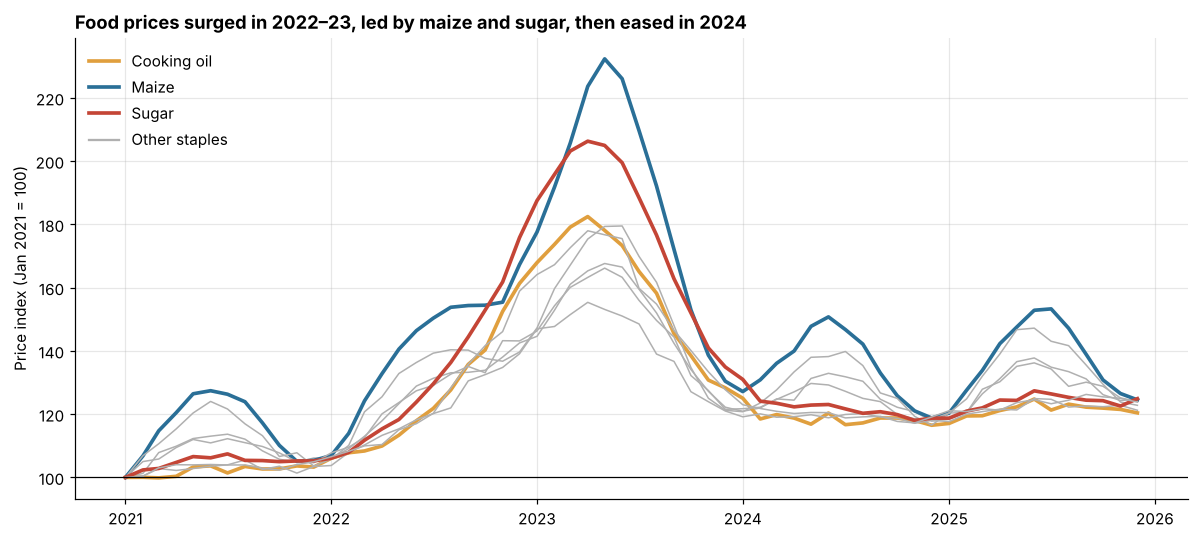

In [3]:
national = df.groupby(["date", "commodity"])["price_index"].mean().unstack()

fig, ax = plt.subplots(figsize=(11, 5))
highlight = {"Sugar": "#c44536", "Cooking oil": "#e09f3e", "Maize": "#2a6f97"}
for col in national.columns:
    if col in highlight:
        ax.plot(national.index, national[col], lw=2.4, color=highlight[col], label=col)
    else:
        ax.plot(national.index, national[col], lw=1, color="#b0b0b0")
ax.plot([], [], color="#b0b0b0", label="Other staples")
ax.axhline(100, color="black", lw=0.8)
ax.set_title("Food prices surged in 2022–23, led by maize and sugar, then eased in 2024",
             loc="left", fontweight="bold")
ax.set_ylabel("Price index (Jan 2021 = 100)")
ax.legend(frameon=False, loc="upper left")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout()
plt.savefig(IMG / "national_price_index.png", dpi=150, bbox_inches="tight")
plt.show()

In [4]:
annual = df.groupby(["commodity", "year"])["price_kes"].mean().unstack().round(0)
annual["Change 2021-23 (%)"] = ((annual[2023] / annual[2021] - 1) * 100).round(0)
annual["Change 2023-25 (%)"] = ((annual[2025] / annual[2023] - 1) * 100).round(0)
annual.sort_values("Change 2021-23 (%)", ascending=False)

year,2021,2022,2023,2024,2025,Change 2021-23 (%),Change 2023-25 (%)
commodity,,,,,,,
Sugar,121.0,153.0,208.0,141.0,143.0,72.0,-31.0
Maize,50.0,62.0,82.0,59.0,60.0,64.0,-27.0
Cooking oil,243.0,298.0,381.0,283.0,288.0,57.0,-24.0
Wheat flour,110.0,134.0,169.0,128.0,132.0,54.0,-22.0
Beans,121.0,141.0,168.0,141.0,145.0,39.0,-14.0
Milk,58.0,68.0,80.0,67.0,69.0,38.0,-14.0
Rice,137.0,161.0,189.0,159.0,162.0,38.0,-14.0
Potatoes,53.0,61.0,73.0,61.0,63.0,38.0,-14.0


## 3. Where are prices highest?

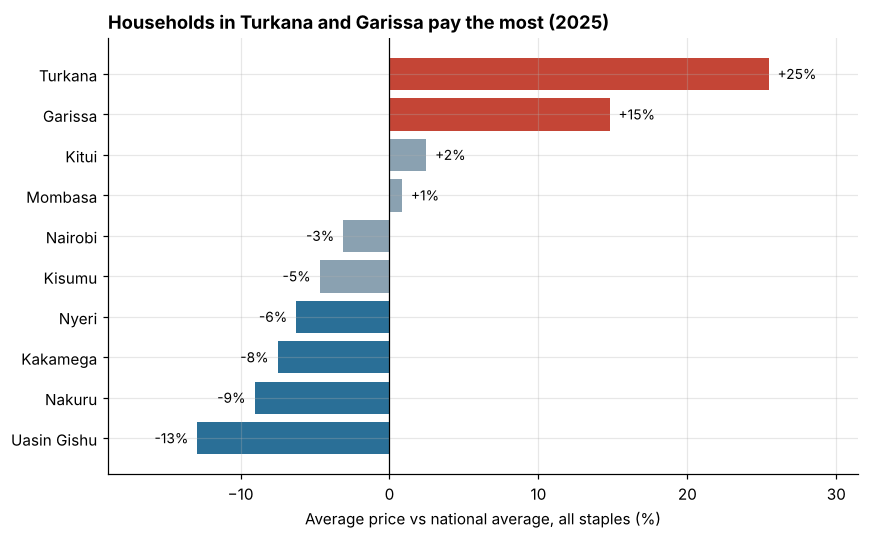

In [5]:
latest = df[df["year"] == 2025]
county_premium = (latest.groupby(["county", "commodity"])["price_kes"].mean()
                  / latest.groupby("commodity")["price_kes"].mean() - 1).groupby("county").mean() * 100
county_premium = county_premium.sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
colors = ["#c44536" if v > 5 else "#2a6f97" if v < -5 else "#8aa1b1" for v in county_premium]
ax.barh(county_premium.index, county_premium.values, color=colors)
ax.axvline(0, color="black", lw=0.8)
for i, v in enumerate(county_premium.values):
    ax.text(v + (0.6 if v >= 0 else -0.6), i, f"{v:+.0f}%", va="center",
            ha="left" if v >= 0 else "right", fontsize=9)
ax.set_title("Households in Turkana and Garissa pay the most (2025)", loc="left", fontweight="bold")
ax.set_xlabel("Average price vs national average, all staples (%)")
ax.set_xlim(county_premium.min() - 6, county_premium.max() + 6)
plt.tight_layout()
plt.savefig(IMG / "county_price_premium.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Seasonality: when is maize cheapest?

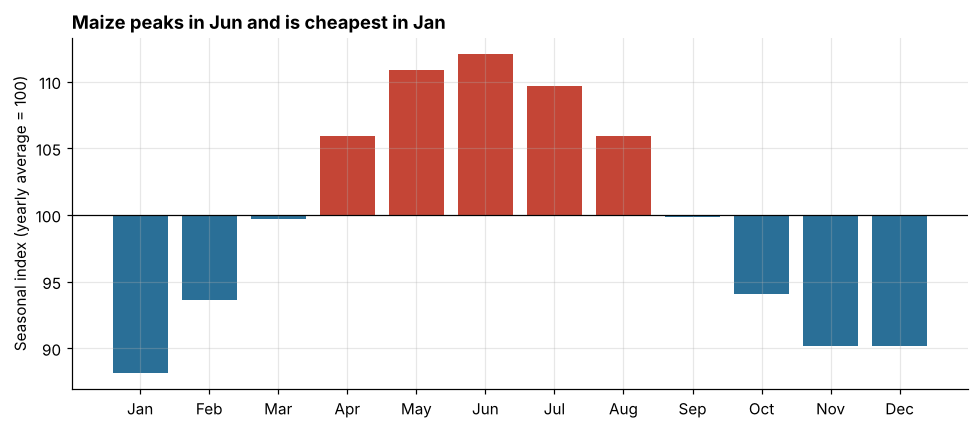

Peak-to-low seasonal swing: 24 points


In [6]:
maize = df[df["commodity"] == "Maize"].copy()
seasonal = maize.groupby("month")["price_index"].mean()
seasonal = seasonal / seasonal.mean() * 100

fig, ax = plt.subplots(figsize=(9, 4))
month_names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
ax.bar(month_names, seasonal.values - 100, bottom=100,
       color=["#c44536" if v > 100 else "#2a6f97" for v in seasonal.values])
ax.axhline(100, color="black", lw=0.8)
ax.set_title(f"Maize peaks in {month_names[seasonal.idxmax()-1]} and is cheapest in "
             f"{month_names[seasonal.idxmin()-1]}", loc="left", fontweight="bold")
ax.set_ylabel("Seasonal index (yearly average = 100)")
plt.tight_layout()
plt.savefig(IMG / "maize_seasonality.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Peak-to-low seasonal swing: {seasonal.max() - seasonal.min():.0f} points")

## 5. Price volatility by commodity

In [7]:
vol = (df.sort_values("date").groupby(["county", "commodity"])["price_kes"]
         .pct_change().groupby(df["commodity"]).std() * 100).sort_values(ascending=False).round(1)
vol.rename("Monthly price volatility (std of % change)").to_frame()

,Monthly price volatility (std of % change)
commodity,
Maize,6.5
Potatoes,5.8
Sugar,5.2
Beans,5.1
Wheat flour,5.0
Milk,4.9
Cooking oil,4.8
Rice,4.7


## Findings

1. **2022–23 price shock:** every staple peaked in 2023. Sugar rose the most, then cooking oil and maize.
2. **Partial relief:** prices fell in 2024 but stayed well above 2021 levels in 2025.
3. **Remote counties pay more:** Turkana and Garissa are the most expensive markets; the Rift Valley grain basket (Uasin Gishu, Nakuru) is the cheapest.
4. **Maize is seasonal:** prices peak before the long-rains harvest and fall after it, so buying and storing after harvest saves money.
5. **Policy angle:** food-aid budgets for arid counties should allow for higher local prices, and price monitoring should focus on the most volatile commodities.